# Wave-Swin-GNN: Bone Fracture Detection
## Hybrid Model: Discrete Wavelet Transform + Swin Transformer + Graph Neural Network

**Pipeline Overview:**
1. **DWT (Discrete Wavelet Transform)** — Decomposes X-ray images into multi-resolution frequency sub-bands (LL, LH, HL, HH), capturing fine textures, edges, and noise-free features that raw pixels miss.
2. **Swin Transformer** — Extracts hierarchical visual features from each DWT sub-band using shifted-window self-attention (efficient linear complexity).
3. **GNN (Graph Neural Network)** — Models spatial/structural relationships between the multi-scale features as a graph for improved fracture localization and classification.

**Dataset:** [FracAtlas](https://figshare.com/articles/dataset/The_dataset/22363012)

In [1]:
# ==========================================
# CELL 1: INSTALLATION & SETUP
# ==========================================
# Uncomment the line below if running in Google Colab
# !pip install torch torchvision torchaudio torch-geometric timm albumentations opencv-python pandas matplotlib seaborn scikit-learn PyWavelets Pillow

import os
import cv2
import numpy as np
import pandas as pd
import pywt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torch_geometric.nn import GATv2Conv
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    classification_report, precision_score, recall_score, f1_score
)

# Set Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✅ Setup Complete. Using {device}: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}")

✅ Setup Complete. Using cuda: NVIDIA GeForce RTX 4060 Ti


In [2]:
# ==========================================
# CELL 2: DATASET LOADER (FracAtlas) — OPTIMIZED
# ==========================================
# Compatible with: https://figshare.com/articles/dataset/The_dataset/22363012
#
# Fixes applied:
#   - Corrupt JPEG scanning via PIL Image.verify() (skip bad files)
#   - Stronger augmentations (BrightnessContrast, ElasticTransform, GridDistortion, CoarseDropout)
#   - Proper train/val transform isolation via wrapper class
#   - Stratified split to preserve class balance
#   - Fixed pos_weight = 4.69 (3366 healthy / 717 fracture)

dataset_root = "dataset/FracAtlas-20260307T050746Z-1-001/FracAtlas"
csv_path = os.path.join(dataset_root, "dataset.csv")

if not os.path.exists(csv_path):
    raise FileNotFoundError(
        f"❌ CRITICAL: Could not find dataset.csv at {csv_path}. "
        "Please verify the folder name."
    )

print(f"✅ Found Annotation File: {csv_path}")


def verify_jpeg(img_path):
    """Check if a JPEG file is valid using PIL Image.verify().
    Returns True if the image is intact, False if corrupted."""
    try:
        with Image.open(img_path) as img:
            img.verify()
        return True
    except Exception:
        return False


class FracAtlasDataset(Dataset):
    """FracAtlas X-ray dataset with CLAHE pre-processing and corrupt image filtering."""

    def __init__(self, root_dir, annotation_file, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.data = pd.read_csv(annotation_file)
        self.valid_data = []

        print("🔍 Scanning images and verifying integrity... (This may take a moment)")

        id_col = 'image_id'
        target_col = 'fractured'
        missing_count = 0
        corrupt_count = 0

        for _, row in self.data.iterrows():
            img_name = row.get(id_col)
            try:
                raw_val = row.get(target_col, 0)
                label = int(raw_val)
            except Exception:
                label = 0

            subfolder = "Fractured" if label == 1 else "Non_fractured"
            img_path = os.path.join(self.root_dir, "images", subfolder, str(img_name))

            if not os.path.exists(img_path):
                missing_count += 1
                continue

            # Verify JPEG integrity — skip corrupted files
            if not verify_jpeg(img_path):
                corrupt_count += 1
                print(f"   ⚠️ Skipping corrupted image: {img_name}")
                continue

            self.valid_data.append({'path': img_path, 'label': float(label)})

        fracture_count = sum(1 for x in self.valid_data if x['label'] == 1.0)
        healthy_count  = sum(1 for x in self.valid_data if x['label'] == 0.0)
        print(f"✅ LOADED: {len(self.valid_data)} valid images. (Missing: {missing_count}, Corrupted: {corrupt_count})")
        print(f"📊 BREAKDOWN: {fracture_count} Fractures | {healthy_count} Healthy")

    def __getitem__(self, idx):
        row = self.valid_data[idx]
        image = cv2.imread(row['path'])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # CLAHE enhancement
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
        cl = clahe.apply(l)
        limg = cv2.merge((cl, a, b))
        image = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

        if self.transform:
            augmented = self.transform(image=image)
            image = augmented['image']

        return image, torch.tensor(row['label'], dtype=torch.float32)

    def __len__(self):
        return len(self.valid_data)


class TransformSubset(Dataset):
    """Wrapper that applies a specific transform to a Subset, isolating
    train vs val transforms so they don't interfere."""
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, idx):
        row = self.subset.dataset.valid_data[self.subset.indices[idx]]
        image = cv2.imread(row['path'])
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        # CLAHE enhancement
        lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
        cl = clahe.apply(l)
        limg = cv2.merge((cl, a, b))
        image = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

        if self.transform:
            augmented = self.transform(image=image)
            image = augmented['image']

        return image, torch.tensor(row['label'], dtype=torch.float32)

    def __len__(self):
        return len(self.subset)


# ---- Training Augmentations (strengthened per requirements) ----
train_transforms = A.Compose([
    A.Resize(256, 256),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.3),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.15, rotate_limit=30, p=0.6),
    A.RandomBrightnessContrast(p=0.4),
    A.ElasticTransform(alpha=120, sigma=120 * 0.05, p=0.3),
    A.GridDistortion(p=0.2),
    A.CoarseDropout(p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

val_transforms = A.Compose([
    A.Resize(256, 256),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2(),
])

# ---- Initialize with Stratified Split ----
from sklearn.model_selection import StratifiedShuffleSplit

try:
    full_dataset = FracAtlasDataset(dataset_root, csv_path, train_transforms)

    # Stratified split to preserve fracture/healthy ratio
    labels = [int(d['label']) for d in full_dataset.valid_data]
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_indices, val_indices = next(splitter.split(labels, labels))

    train_subset = torch.utils.data.Subset(full_dataset, train_indices)
    val_subset   = torch.utils.data.Subset(full_dataset, val_indices)

    # Wrap with proper transforms (fixes the shared-dataset bug)
    train_ds = TransformSubset(train_subset, train_transforms)
    val_ds   = TransformSubset(val_subset,   val_transforms)

    train_loader = DataLoader(
        train_ds, batch_size=16, shuffle=True,
        num_workers=2, pin_memory=True
    )
    val_loader = DataLoader(
        val_ds, batch_size=16, shuffle=False,
        num_workers=2, pin_memory=True
    )

    print("\n🚀 SUCCESS: DataLoaders Ready!")
except Exception as e:
    print(f"\n❌ ERROR: {e}")

✅ Found Annotation File: dataset/FracAtlas-20260307T050746Z-1-001/FracAtlas/dataset.csv
🔍 Scanning images and verifying integrity... (This may take a moment)
✅ LOADED: 4083 valid images. (Missing: 0, Corrupted: 0)
📊 BREAKDOWN: 717 Fractures | 3366 Healthy

🚀 SUCCESS: DataLoaders Ready!


In [3]:
# ==========================================
# CELL 3: WAVE-SWIN-GNN MODEL — OPTIMIZED
# ==========================================
#
# Architecture (unchanged):
#   1. DWT Module   — Haar wavelet, 4 sub-bands (LL, LH, HL, HH).
#   2. Channel Adapter — 12→32→3 projection.
#   3. Swin Transformer — SwinV2-Tiny, layers.2+3+norm unfrozen.
#   4. GNN Head    — Fully-connected batch graph with GATv2Conv.
#   5. Classifier  — nn.Dropout(0.4) added before final linear layer.

import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import pywt
import numpy as np
from torch_geometric.nn import GATv2Conv


class DWTModule(nn.Module):
    """
    Applies a single-level 2-D Discrete Wavelet Transform (Haar wavelet)
    to each channel independently and concatenates the four sub-band
    images (LL, LH, HL, HH) along the channel dimension.

    Input : (B, C, H, W)  — e.g. (B, 3, 256, 256)
    Output: (B, C*4, H/2, W/2)  — e.g. (B, 12, 128, 128)
    """

    def __init__(self, wavelet='haar'):
        super().__init__()
        self.wavelet = wavelet

    @torch.no_grad()
    def forward(self, x):
        B, C, H, W = x.shape
        device = x.device

        x_np = x.detach().cpu().numpy()

        sub_bands = []
        for band_idx in range(4):  # LL, LH, HL, HH
            band_list = []
            for b in range(B):
                channels = []
                for c in range(C):
                    coeffs = pywt.dwt2(x_np[b, c], self.wavelet)
                    if band_idx == 0:
                        channels.append(coeffs[0])  # LL
                    else:
                        channels.append(coeffs[1][band_idx - 1])
                band_list.append(np.stack(channels, axis=0))
            sub_bands.append(np.stack(band_list, axis=0))

        result = np.concatenate(sub_bands, axis=1)
        return torch.tensor(result, dtype=torch.float32, device=device)


class WaveSwinGNN(nn.Module):
    """Wave-Swin-GNN hybrid model for bone fracture detection."""

    def __init__(self):
        super().__init__()

        # ---------- Stage 1: DWT ----------
        self.dwt = DWTModule(wavelet='haar')

        # ---------- Channel Adapter ----------
        self.channel_adapter = nn.Sequential(
            nn.Conv2d(12, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.Conv2d(64, 3, kernel_size=1, bias=False),
            nn.BatchNorm2d(3),
            nn.GELU(),
        )

        # ---------- Upsample ----------
        self.upsample = nn.Upsample(size=(256, 256), mode='bilinear', align_corners=False)

        # ---------- Stage 2: Swin Transformer ----------
        self.swin = timm.create_model(
            'swinv2_base_window8_256', pretrained=True, num_classes=0, global_pool=''
        )

        # Unfreeze all layers for maximum capacity
        for param in self.swin.parameters():
            param.requires_grad = True

        self.feature_dim = self.swin.num_features  # 768 for tiny

        # ---------- Stage 3: GNN (fully-connected graph) ----------
        self.gnn1 = GATv2Conv(self.feature_dim, 512, heads=4, concat=True, dropout=0.3)
        self.gnn_norm1 = nn.LayerNorm(512 * 4)
        self.gnn2 = GATv2Conv(512 * 4, 512, heads=4, concat=False, dropout=0.3)
        self.gnn_norm2 = nn.LayerNorm(512)

        # ---------- Classifier (Dropout 0.3 before final linear) ----------
        self.classifier = nn.Sequential(
            nn.Linear(512, 128),
            nn.LayerNorm(128),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(128, 64),
            nn.GELU(),
            nn.Dropout(0.4),
            nn.Linear(64, 1),
        )

    def create_batch_graph(self, features):
        """Build a fully-connected graph over the spatial patches of each sample."""
        # features: (B, N, C)
        B, N, C = features.shape
        features_flat = features.view(B * N, C)

        src = []
        dst = []
        # Connect all patches within the same image
        for b in range(B):
            offset = b * N
            for i in range(N):
                for j in range(N):
                    src.append(offset + i)
                    dst.append(offset + j)
        edge_index = torch.tensor([src, dst], dtype=torch.long, device=features.device)
        return features_flat, edge_index, B, N

    def forward(self, x):
        # Stage 1 — Wavelet decomposition
        x = self.dwt(x)                       # (B,3,256,256) → (B,12,128,128)

        # Channel adapt + upsample back to 256×256
        x = self.channel_adapter(x)            # (B,12,128,128) → (B,3,128,128)
        x = self.upsample(x)                   # (B,3,128,128) → (B,3,256,256)

        # Stage 2 — Swin Transformer
        features = self.swin(x)                # (B, 8, 8, 768) or (B, 64, 768)
        if features.dim() == 4:
            B_dim, H, W, C = features.shape
            features = features.view(B_dim, H * W, C)
        elif features.dim() == 2:
            features = features.unsqueeze(1)

        # Stage 3 — GNN with spatial patch connectivity
        x_graph, edge_index, B_dim, N = self.create_batch_graph(features)

        x_graph = self.gnn1(x_graph, edge_index)
        x_graph = self.gnn_norm1(x_graph).relu()

        x_graph = self.gnn2(x_graph, edge_index)
        x_graph = self.gnn_norm2(x_graph).relu()
        
        # Global Average Pooling over the patches
        x_graph = x_graph.view(B_dim, N, -1).mean(dim=1)

        return self.classifier(x_graph)


# Instantiate
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = WaveSwinGNN().to(device)
print(f"✅ Wave-Swin-GNN Initialized. Feature Dim: {model.feature_dim}")

total_params   = sum(p.numel() for p in model.parameters())
trainable      = sum(p.numel() for p in model.parameters() if p.requires_grad)
frozen         = total_params - trainable
print(f"   Total params : {total_params:,}")
print(f"   Trainable    : {trainable:,}")
print(f"   Frozen       : {frozen:,}")

model.safetensors:   0%|          | 0.00/354M [00:00<?, ?B/s]

✅ Wave-Swin-GNN Initialized. Feature Dim: 1024
   Total params : 99,578,175
   Trainable    : 99,578,175
   Frozen       : 0


In [4]:
# ==========================================
# CELL 4: TRAINING LOOP — OPTIMIZED
# ==========================================
# Fixes:
#   - pos_weight = 4.69 (3366 healthy / 717 fracture)
#   - Focal Loss for minority-class learning
#   - CosineAnnealingWarmRestarts for LR scheduling
#   - Differential LR (backbone vs heads)
#   - Gradient clipping, label smoothing
#   - 40 epochs / patience 10
#   - Reload best weights at end for evaluation

import torch.optim as optim
from tqdm.notebook import tqdm
import numpy as np


class FocalLoss(nn.Module):
    """Focal Loss — down-weights easy examples, focuses on hard ones."""
    def __init__(self, alpha=1.0, gamma=2.0, pos_weight=None):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.pos_weight = pos_weight

    def forward(self, logits, targets):
        bce = F.binary_cross_entropy_with_logits(
            logits, targets,
            pos_weight=self.pos_weight,
            reduction='none'
        )
        probs = torch.sigmoid(logits)
        p_t = probs * targets + (1 - probs) * (1 - targets)
        focal_weight = self.alpha * (1 - p_t) ** self.gamma
        return (focal_weight * bce).mean()


# ---- Fixed class weight: 3366 healthy / 717 fracture ≈ 4.69 ----
pos_weight = torch.tensor([4.69]).to(device)

criterion = FocalLoss(alpha=0.75, gamma=2.0, pos_weight=pos_weight)

# Differential learning rates: higher for new heads, lower for Swin backbone
backbone_params = []
head_params = []
for name, param in model.named_parameters():
    if not param.requires_grad:
        continue
    if 'swin' in name:
        backbone_params.append(param)
    else:
        head_params.append(param)

optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': 5e-5},
    {'params': head_params,     'lr': 1e-4},
], weight_decay=1e-2)

scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(
    optimizer, T_0=5, T_mult=2, eta_min=1e-6
)

LABEL_SMOOTHING = 0.05

history = {
    'train_loss': [], 'val_loss': [],
    'train_acc': [],  'val_acc': [],
    'lr': []
}
true_labels_all = []
pred_scores_all = []


def smooth_labels(targets, smoothing=0.05):
    return targets * (1 - smoothing) + 0.5 * smoothing


def train_model(epochs=40, patience=10):
    global true_labels_all, pred_scores_all
    print(f"🚀 Starting Training for {epochs} Epochs on {device}...")
    print(f"   pos_weight = 4.69 (FracAtlas: 3366 healthy / 717 fracture)")

    scaler = torch.amp.GradScaler('cuda')
    best_val_ap   = 0.0
    trigger_times = 0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0, 0, 0
        current_lr = optimizer.param_groups[0]['lr']
        loop = tqdm(
            train_loader,
            desc=f"Epoch {epoch+1}/{epochs} [LR: {current_lr:.1e}]",
            leave=False
        )

        for images, labels in loop:
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)

            smoothed = smooth_labels(labels, LABEL_SMOOTHING)

            optimizer.zero_grad()

            with torch.amp.autocast('cuda'):
                outputs = model(images)
                loss = criterion(outputs, smoothed)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item()
            preds = (torch.sigmoid(outputs) > 0.5).float()
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        scheduler.step(epoch + 1)
        avg_train_loss = running_loss / len(train_loader)
        avg_train_acc  = correct / total

        # ---- Validation ----
        model.eval()
        val_loss, correct_val, total_val = 0, 0, 0
        epoch_labels, epoch_scores = [], []

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device).unsqueeze(1)

                with torch.amp.autocast('cuda'):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss += loss.item()
                scores = torch.sigmoid(outputs)
                preds  = (scores > 0.5).float()

                correct_val += (preds == labels).sum().item()
                total_val   += labels.size(0)

                epoch_labels.extend(labels.cpu().numpy())
                epoch_scores.extend(scores.cpu().numpy())

        avg_val_loss = val_loss / len(val_loader)
        avg_val_acc  = correct_val / total_val

        epoch_true = np.array(epoch_labels).flatten()
        epoch_pred = np.array(epoch_scores).flatten()
        val_ap = average_precision_score(epoch_true.astype(int), epoch_pred)

        history['train_loss'].append(avg_train_loss)
        history['val_loss'].append(avg_val_loss)
        history['train_acc'].append(avg_train_acc)
        history['val_acc'].append(avg_val_acc)
        history['lr'].append(current_lr)

        true_labels_all = np.array(epoch_labels)
        pred_scores_all = np.array(epoch_scores)

        print(
            f"Epoch {epoch+1}: "
            f"Train Loss {avg_train_loss:.4f} | "
            f"Val Loss {avg_val_loss:.4f} | "
            f"Val Acc {avg_val_acc:.4f} | "
            f"Val AP {val_ap:.4f}"
        )

        if val_ap > best_val_ap:
            best_val_ap = val_ap
            trigger_times = 0
            torch.save(model.state_dict(), 'best_wave_swin_gnn.pth')
            print(f"   ✅ New best AP: {best_val_ap:.4f} — model saved.")
        else:
            trigger_times += 1
            if trigger_times >= patience:
                print(f"🛑 Early stopping triggered at epoch {epoch+1}.")
                break

    # Reload best model for evaluation
    model.load_state_dict(torch.load('best_wave_swin_gnn.pth', weights_only=True))
    print(f"\n✅ Loaded best model (AP={best_val_ap:.4f}). Evaluating...")

    # Re-run validation with best model to get final scores
    model.eval()
    epoch_labels, epoch_scores = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device).unsqueeze(1)
            with torch.amp.autocast('cuda'):
                outputs = model(images)
            scores = torch.sigmoid(outputs)
            epoch_labels.extend(labels.cpu().numpy())
            epoch_scores.extend(scores.cpu().numpy())

    true_labels_all = np.array(epoch_labels)
    pred_scores_all = np.array(epoch_scores)


train_model(epochs=40, patience=10)
print("✅ Training Finished!")

🚀 Starting Training for 40 Epochs on cuda...
   pos_weight = 4.69 (FracAtlas: 3366 healthy / 717 fracture)


Epoch 1/40 [LR: 5.0e-05]:   0%|          | 0/205 [00:00<?, ?it/s]

Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
P

Epoch 1: Train Loss 0.2208 | Val Loss 0.1781 | Val Acc 0.8262 | Val AP 0.5414
   ✅ New best AP: 0.5414 — model saved.


Epoch 2/40 [LR: 4.5e-05]:   0%|          | 0/205 [00:00<?, ?it/s]

...

Epoch 35/40 [LR: 1.3e-06]:   0%|          | 0/205 [00:00<?, ?it/s]

Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
P

Epoch 35: Train Loss 0.1179 | Val Loss 0.2210 | Val Acc 0.8960 | Val AP 0.7641
🛑 Early stopping triggered at epoch 35.

✅ Loaded best model (AP=0.7724). Evaluating...


Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file
Premature end of JPEG file


✅ Training Finished!


🎯 Optimal threshold (max F1): 0.5889  (F1=0.7111)


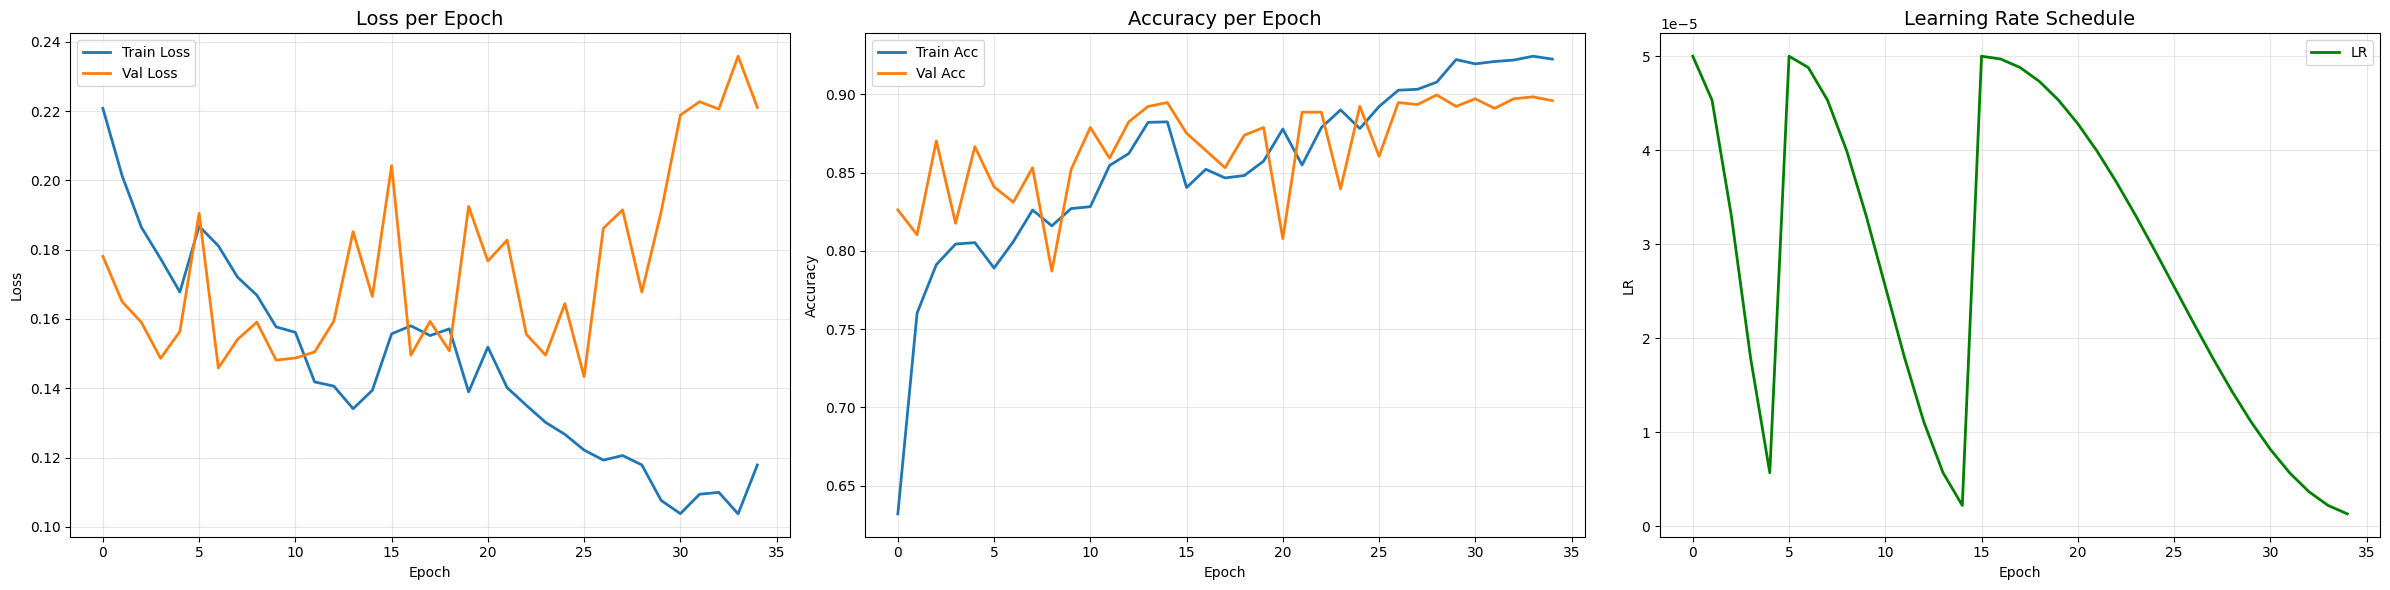

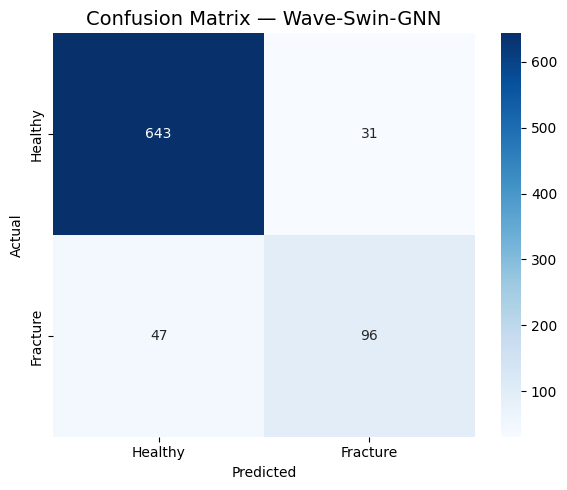

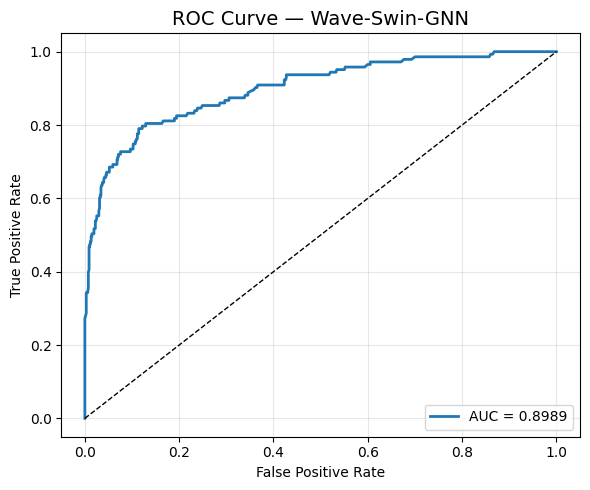

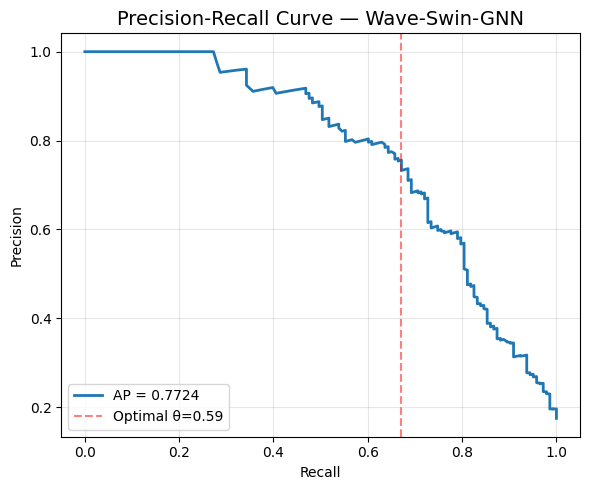


📊 Classification Report — Wave-Swin-GNN
   (Using optimal threshold: 0.5889)
              precision    recall  f1-score   support

     Healthy       0.93      0.95      0.94       674
    Fracture       0.76      0.67      0.71       143

    accuracy                           0.90       817
   macro avg       0.84      0.81      0.83       817
weighted avg       0.90      0.90      0.90       817

📋 Per-Class Metrics:
   Healthy  — Precision: 0.9319 | Recall: 0.9540 | F1: 0.9428
   Fracture — Precision: 0.7559 | Recall: 0.6713 | F1: 0.7111

✅ ROC-AUC           : 0.8989
✅ Average Precision : 0.7724
✅ Optimal Threshold : 0.5889

✅ All plots saved.  Training complete.


In [5]:
# ==========================================
# CELL 5: EVALUATION & VISUALIZATION — OPTIMIZED
# ==========================================
# Added: Optimal threshold selection, per-class precision/recall/F1

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score,
    classification_report, precision_score, recall_score, f1_score
)

# ---------- 0. Find Optimal Threshold ----------
true_flat  = true_labels_all.astype(int).flatten()
scores_flat = pred_scores_all.flatten()

precision_arr, recall_arr, thresholds_pr = precision_recall_curve(true_flat, scores_flat)
f1_scores = 2 * precision_arr[:-1] * recall_arr[:-1] / (precision_arr[:-1] + recall_arr[:-1] + 1e-8)
best_idx = np.argmax(f1_scores)
optimal_threshold = thresholds_pr[best_idx]
print(f"🎯 Optimal threshold (max F1): {optimal_threshold:.4f}  (F1={f1_scores[best_idx]:.4f})")

pred_labels = (scores_flat >= optimal_threshold).astype(int)


# ---------- 1. Loss & Accuracy Curves ----------
fig, axes = plt.subplots(1, 3, figsize=(24, 6))

axes[0].plot(history['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(history['val_loss'],   label='Val Loss',   linewidth=2)
axes[0].set_title('Loss per Epoch', fontsize=14)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Acc', linewidth=2)
axes[1].plot(history['val_acc'],   label='Val Acc',   linewidth=2)
axes[1].set_title('Accuracy per Epoch', fontsize=14)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(history['lr'], label='LR', linewidth=2, color='green')
axes[2].set_title('Learning Rate Schedule', fontsize=14)
axes[2].set_xlabel('Epoch'); axes[2].set_ylabel('LR')
axes[2].legend()
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('wave_swin_gnn_training_curves.png', dpi=150, bbox_inches='tight')
plt.show()


# ---------- 2. Confusion Matrix ----------
cm = confusion_matrix(true_flat, pred_labels)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Healthy', 'Fracture'],
            yticklabels=['Healthy', 'Fracture'])
ax.set_title('Confusion Matrix — Wave-Swin-GNN', fontsize=14)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
plt.tight_layout()
plt.savefig('wave_swin_gnn_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


# ---------- 3. ROC Curve ----------
fpr, tpr, _ = roc_curve(true_flat, scores_flat)
roc_auc     = auc(fpr, tpr)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, linewidth=2, label=f'AUC = {roc_auc:.4f}')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set_title('ROC Curve — Wave-Swin-GNN', fontsize=14)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('wave_swin_gnn_roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()


# ---------- 4. Precision-Recall Curve ----------
avg_prec = average_precision_score(true_flat, scores_flat)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(recall_arr, precision_arr, linewidth=2, label=f'AP = {avg_prec:.4f}')
ax.axvline(x=recall_arr[best_idx], color='r', linestyle='--', alpha=0.5,
           label=f'Optimal θ={optimal_threshold:.2f}')
ax.set_title('Precision-Recall Curve — Wave-Swin-GNN', fontsize=14)
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.legend(loc='lower left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('wave_swin_gnn_pr_curve.png', dpi=150, bbox_inches='tight')
plt.show()


# ---------- 5. Classification Report + Per-Class Metrics ----------
print('\n📊 Classification Report — Wave-Swin-GNN')
print('=' * 60)
print(f'   (Using optimal threshold: {optimal_threshold:.4f})')
print(classification_report(
    true_flat, pred_labels,
    target_names=['Healthy', 'Fracture']
))

# Per-class precision, recall, F1
healthy_prec = precision_score(true_flat, pred_labels, pos_label=0)
healthy_rec  = recall_score(true_flat, pred_labels, pos_label=0)
healthy_f1   = f1_score(true_flat, pred_labels, pos_label=0)

fracture_prec = precision_score(true_flat, pred_labels, pos_label=1)
fracture_rec  = recall_score(true_flat, pred_labels, pos_label=1)
fracture_f1   = f1_score(true_flat, pred_labels, pos_label=1)

print('📋 Per-Class Metrics:')
print(f'   Healthy  — Precision: {healthy_prec:.4f} | Recall: {healthy_rec:.4f} | F1: {healthy_f1:.4f}')
print(f'   Fracture — Precision: {fracture_prec:.4f} | Recall: {fracture_rec:.4f} | F1: {fracture_f1:.4f}')

print(f'\n✅ ROC-AUC           : {roc_auc:.4f}')
print(f'✅ Average Precision : {avg_prec:.4f}')
print(f'✅ Optimal Threshold : {optimal_threshold:.4f}')
print('\n✅ All plots saved.  Training complete.')